<a href="https://colab.research.google.com/github/Faithieeeee/LLM-classification-Api/blob/main/LLM_CLASSIFICATION_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Import the libraries we need

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)


Libraries imported successfully!
Pandas version: 2.2.3


In [2]:
from google.colab import drive

drive.mount('/content/gdrive')


Mounted at /content/gdrive


In [3]:
import os
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
PROJECT_PATH = '/content/gdrive/MyDrive/LLM_Classification_Project'

DATA_PATH = os.path.join(PROJECT_PATH, 'data')
RESULTS_PATH = os.path.join(PROJECT_PATH, 'results')

os.makedirs(DATA_PATH, exist_ok=True)
os.makedirs(RESULTS_PATH, exist_ok=True)

print("Project directory connected!")
print("Files in data folder:", os.listdir(DATA_PATH))

Project directory connected!
Files in data folder: ['customer_churn_data.csv', 'loan_approval_dataset.csv']


In [5]:
# Load the datasets

churn_df = pd.read_csv(os.path.join(DATA_PATH, 'customer_churn_data.csv'))

loan_df = pd.read_csv(os.path.join(DATA_PATH, 'loan_approval_dataset.csv'))

print("CUSTOMER CHURN DATASET")
print("Shape:", churn_df.shape)
display(churn_df.head())

print("\nLOAN APPROVAL DATASET")
print("Shape:", loan_df.shape)
display(loan_df.head())

CUSTOMER CHURN DATASET
Shape: (5880, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CUST0000,Male,0,No,Yes,23,No,No phone service,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer,49.85,1146.55,No
1,CUST0001,Female,0,Yes,No,43,No,No phone service,DSL,Yes,...,Yes,No,Yes,No,Month-to-month,No,Mailed check,100.70,4330.10,Yes
2,CUST0002,Male,1,No,No,51,Yes,No,DSL,No,...,Yes,Yes,No,No,One year,No,Electronic check,97.33,4963.83,Yes
3,CUST0003,Male,1,No,No,72,Yes,Yes,DSL,Yes,...,Yes,No,No,No,Month-to-month,No,Credit card,101.38,7299.36,No
4,CUST0004,Male,1,No,No,25,Yes,Yes,DSL,No,...,No,Yes,No,Yes,Month-to-month,No,Electronic check,52.22,1305.50,Yes



LOAN APPROVAL DATASET
Shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [6]:
print("CHURN DATASET INFORMATION")
churn_df.info()

print("\nLOAN DATASET INFORMATION")
loan_df.info()

CHURN DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5880 entries, 0 to 5879
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5880 non-null   object 
 1   gender            5880 non-null   object 
 2   SeniorCitizen     5880 non-null   int64  
 3   Partner           5880 non-null   object 
 4   Dependents        5880 non-null   object 
 5   tenure            5880 non-null   int64  
 6   PhoneService      5880 non-null   object 
 7   MultipleLines     5880 non-null   object 
 8   InternetService   5880 non-null   object 
 9   OnlineSecurity    5880 non-null   object 
 10  OnlineBackup      5880 non-null   object 
 11  DeviceProtection  5880 non-null   object 
 12  TechSupport       5880 non-null   object 
 13  StreamingTV       5880 non-null   object 
 14  StreamingMovies   5880 non-null   object 
 15  Contract          5880 non-null   object 
 16  PaperlessBilling

In [7]:
print("CHURN MISSING VALUES")
display(churn_df.isnull().sum())

print("\nLOAN MISSING VALUES")
display(loan_df.isnull().sum())

CHURN MISSING VALUES


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



LOAN MISSING VALUES


,0
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0


In [8]:
print("LOAN DATASET COLUMNS:")

for col in loan_df.columns:
    print(repr(col))

LOAN DATASET COLUMNS:
'loan_id'
' no_of_dependents'
' education'
' self_employed'
' income_annum'
' loan_amount'
' loan_term'
' cibil_score'
' residential_assets_value'
' commercial_assets_value'
' luxury_assets_value'
' bank_asset_value'
' loan_status'


In [9]:
# Remove leading/trailing spaces from column names
churn_df.columns = churn_df.columns.str.strip()
loan_df.columns = loan_df.columns.str.strip()

print(loan_df.columns.tolist())

['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


In [10]:
print("LOAN DATASET")

print("Duplicate rows:", loan_df.duplicated().sum())

print("\nTarget distribution:")
print(loan_df['loan_status'].value_counts())

print("\nTarget distribution (%):")
print(
    loan_df['loan_status']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nUnique target values:")
print(loan_df['loan_status'].unique())

LOAN DATASET
Duplicate rows: 0

Target distribution:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

Target distribution (%):
loan_status
Approved    62.22
Rejected    37.78
Name: proportion, dtype: float64

Unique target values:
[' Approved' ' Rejected']


In [11]:
# Numerical feature statistics

print("CHURN NUMERICAL STATISTICS")
display(churn_df.describe())

print("LOAN NUMERICAL STATISTICS")
display(loan_df.describe())

CHURN NUMERICAL STATISTICS


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,5880.000000,5880.000000,5880.000000,5880.000000
mean,0.500680,36.549150,70.157779,2566.813165
std,0.500042,20.909674,28.804615,1910.017743
min,0.000000,1.000000,20.000000,20.030000
25%,0.000000,18.000000,45.717500,1020.217500
50%,1.000000,37.000000,70.155000,2136.445000
75%,1.000000,55.000000,95.457500,3767.665000
max,1.000000,72.000000,119.990000,8589.600000


LOAN NUMERICAL STATISTICS


,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [12]:
# Inspect categorical values

for name, df in [("CHURN", churn_df), ("LOAN", loan_df)]:
    print(f"\n{name} CATEGORICAL VALUES")

    for col in df.select_dtypes(include='object').columns:
        print(f"\n{col}:")
        print(df[col].value_counts().to_dict())


CHURN CATEGORICAL VALUES

customerID:
{'CUST0000': 1, 'CUST0001': 1, 'CUST0002': 1, 'CUST0003': 1, 'CUST0004': 1, 'CUST0005': 1, 'CUST0006': 1, 'CUST0007': 1, 'CUST0008': 1, 'CUST0009': 1, 'CUST0010': 1, 'CUST0011': 1, 'CUST0012': 1, 'CUST0013': 1, 'CUST0014': 1, 'CUST0015': 1, 'CUST0016': 1, 'CUST0017': 1, 'CUST0018': 1, 'CUST0019': 1, 'CUST0020': 1, 'CUST0021': 1, 'CUST0022': 1, 'CUST0023': 1, 'CUST0024': 1, 'CUST0025': 1, 'CUST0026': 1, 'CUST0027': 1, 'CUST0028': 1, 'CUST0029': 1, 'CUST0030': 1, 'CUST0031': 1, 'CUST0032': 1, 'CUST0033': 1, 'CUST0034': 1, 'CUST0035': 1, 'CUST0036': 1, 'CUST0037': 1, 'CUST0038': 1, 'CUST0039': 1, 'CUST0040': 1, 'CUST0041': 1, 'CUST0042': 1, 'CUST0043': 1, 'CUST0044': 1, 'CUST0045': 1, 'CUST0046': 1, 'CUST0047': 1, 'CUST0048': 1, 'CUST0049': 1, 'CUST0050': 1, 'CUST0051': 1, 'CUST0052': 1, 'CUST0053': 1, 'CUST0054': 1, 'CUST0055': 1, 'CUST0056': 1, 'CUST0057': 1, 'CUST0058': 1, 'CUST0059': 1, 'CUST0060': 1, 'CUST0061': 1, 'CUST0062': 1, 'CUST0063': 1, 

In [13]:
# DATA QUALITY CHECK

print("LOAN STATUS DISTRIBUTION")
print(loan_df['loan_status'].value_counts())
print(loan_df['loan_status'].value_counts(normalize=True) * 100)

print("\nNEGATIVE LOAN VALUES")
print(loan_df.select_dtypes(include='number').lt(0).sum())

print("\nRECORDS WITH NEGATIVE RESIDENTIAL ASSETS")
display(loan_df[loan_df['residential_assets_value'] < 0])

print("\nCHURN CATEGORICAL VALUES")
for col in churn_df.select_dtypes(include='object').columns:
    print(col, churn_df[col].unique())

print("\nLOAN CATEGORICAL VALUES")
for col in loan_df.select_dtypes(include='object').columns:
    print(col, loan_df[col].unique())

LOAN STATUS DISTRIBUTION
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64
loan_status
Approved    62.215976
Rejected    37.784024
Name: proportion, dtype: float64

NEGATIVE LOAN VALUES
loan_id                      0
no_of_dependents             0
income_annum                 0
loan_amount                  0
loan_term                    0
cibil_score                  0
residential_assets_value    28
commercial_assets_value      0
luxury_assets_value          0
bank_asset_value             0
dtype: int64

RECORDS WITH NEGATIVE RESIDENTIAL ASSETS


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
59,60,4,Not Graduate,Yes,5500000,18200000,16,797,-100000,4900000,18600000,4800000,Approved
196,197,4,Not Graduate,Yes,400000,1500000,2,669,-100000,600000,900000,500000,Approved
559,560,2,Graduate,Yes,200000,500000,6,885,-100000,0,300000,200000,Rejected
702,703,4,Graduate,Yes,6300000,23900000,6,899,-100000,11400000,20600000,6700000,Approved
737,738,2,Graduate,Yes,900000,2500000,16,458,-100000,100000,3200000,1100000,Rejected
784,785,0,Graduate,No,5000000,14400000,2,761,-100000,7300000,12600000,4500000,Approved
904,905,2,Graduate,No,4100000,14900000,12,571,-100000,5200000,13000000,3400000,Approved
1089,1090,3,Graduate,No,5100000,11000000,6,336,-100000,5800000,11600000,7500000,Rejected
1163,1164,2,Graduate,No,4500000,9100000,18,593,-100000,600000,12400000,2500000,Approved
1350,1351,5,Graduate,No,4000000,13700000,6,496,-100000,1400000,15800000,3700000,Rejected



CHURN CATEGORICAL VALUES
customerID ['CUST0000' 'CUST0001' 'CUST0002' ... 'CUST5877' 'CUST5878' 'CUST5879']
gender ['Male' 'Female']
Partner ['No' 'Yes']
Dependents ['Yes' 'No']
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['No' 'DSL' 'Fiber optic']
OnlineSecurity ['No internet service' 'Yes' 'No']
OnlineBackup ['No internet service' 'No' 'Yes']
DeviceProtection ['No internet service' 'Yes' 'No']
TechSupport ['No internet service' 'No' 'Yes']
StreamingTV ['No internet service' 'Yes' 'No']
StreamingMovies ['No internet service' 'No' 'Yes']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Bank transfer' 'Mailed check' 'Electronic check' 'Credit card']
Churn ['No' 'Yes']

LOAN CATEGORICAL VALUES
education [' Graduate' ' Not Graduate']
self_employed [' No' ' Yes']
loan_status [' Approved' ' Rejected']


In [14]:

# DATA CLEANING AND PREPARATION

# 1. Remove unnecessary spaces from column names and text values
for df in [churn_df, loan_df]:
    df.columns = df.columns.str.strip()

    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].str.strip()

# 2. Replace the invalid residential asset values with NaN
loan_df['residential_assets_value'] = (
    loan_df['residential_assets_value'].replace(-100000, np.nan)
)

# 3. Separate features (X) and target (y)
# Remove customerID and loan_id because they are identifiers.

X_churn = churn_df.drop(columns=['Churn', 'customerID'])
y_churn = churn_df['Churn']

X_loan = loan_df.drop(columns=['loan_status', 'loan_id'])
y_loan = loan_df['loan_status']

# 4. Split each dataset into training and testing sets
# Stratification preserves the target class proportions.

X_churn_train, X_churn_test, y_churn_train, y_churn_test = train_test_split(
    X_churn, y_churn,
    test_size=0.2,
    random_state=42,
    stratify=y_churn
)

X_loan_train, X_loan_test, y_loan_train, y_loan_test = train_test_split(
    X_loan, y_loan,
    test_size=0.2,
    random_state=42,
    stratify=y_loan
)

print("CHURN TRAINING DATA:", X_churn_train.shape)
print("CHURN TEST DATA:", X_churn_test.shape)

print("\nLOAN TRAINING DATA:", X_loan_train.shape)
print("LOAN TEST DATA:", X_loan_test.shape)

print("\nLoan missing values after cleaning:")
print(X_loan.isnull().sum())


CHURN TRAINING DATA: (4704, 19)
CHURN TEST DATA: (1176, 19)

LOAN TRAINING DATA: (3415, 11)
LOAN TEST DATA: (854, 11)

Loan missing values after cleaning:
no_of_dependents             0
education                    0
self_employed                0
income_annum                 0
loan_amount                  0
loan_term                    0
cibil_score                  0
residential_assets_value    28
commercial_assets_value      0
luxury_assets_value          0
bank_asset_value             0
dtype: int64


In [15]:

# STEP 9: BUILD PREPROCESSING PIPELINES

def create_preprocessor(X):
    numerical_columns = X.select_dtypes(include=np.number).columns.tolist()
    categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()

    numerical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer([
        ('numerical', numerical_pipeline, numerical_columns),
        ('categorical', categorical_pipeline, categorical_columns)
    ])

    return preprocessor


# Create a separate preprocessor for each dataset
churn_preprocessor = create_preprocessor(X_churn_train)
loan_preprocessor = create_preprocessor(X_loan_train)

print("Preprocessing pipelines created successfully!")


Preprocessing pipelines created successfully!


In [16]:

# STEP 10: TRAIN AND EVALUATE TRADITIONAL ML MODELS

def evaluate_model(model, X_test, y_test, positive_label):
    predictions = model.predict(X_test)

    results = {
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions, pos_label=positive_label, zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, pos_label=positive_label, zero_division=0
        ),
        'F1-score': f1_score(
            y_test, predictions, pos_label=positive_label, zero_division=0
        )
    }

    print("\nClassification Report:")
    print(classification_report(y_test, predictions, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    return results


# Store trained models and their results
trained_models = {}
all_results = []


# Define the two datasets
datasets = {
    'Churn': (X_churn_train, X_churn_test, y_churn_train, y_churn_test,
              churn_preprocessor, 'Yes'),

    'Loan Approval': (X_loan_train, X_loan_test, y_loan_train, y_loan_test,
                      loan_preprocessor, 'Approved')
}


for dataset_name, (X_train, X_test, y_train, y_test,
                   preprocessor, positive_label) in datasets.items():

    print("\n" + "=" * 50)
    print(dataset_name.upper())
    print("=" * 50)

    models = {
        'Logistic Regression': LogisticRegression(max_iter=1000),
        'Random Forest': RandomForestClassifier(
            n_estimators=200,
            random_state=42
        )
    }

    for model_name, classifier in models.items():

        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('classifier', classifier)
        ])

        print(f"\nTraining {model_name}...")

        pipeline.fit(X_train, y_train)

        print(f"\n{model_name} Results:")

        metrics = evaluate_model(
            pipeline, X_test, y_test, positive_label
        )

        trained_models[(dataset_name, model_name)] = pipeline

        all_results.append({
            'Dataset': dataset_name,
            'Model': model_name,
            **metrics
        })


# Create a comparison table
results_df = pd.DataFrame(all_results)

display(results_df.round(4))



CHURN

Training Logistic Regression...

Logistic Regression Results:

Classification Report:
              precision    recall  f1-score   support

          No       0.51      0.60      0.55       596
         Yes       0.49      0.40      0.44       580

    accuracy                           0.50      1176
   macro avg       0.50      0.50      0.50      1176
weighted avg       0.50      0.50      0.50      1176

Confusion Matrix:
[[357 239]
 [348 232]]

Training Random Forest...

Random Forest Results:

Classification Report:
              precision    recall  f1-score   support

          No       0.49      0.51      0.50       596
         Yes       0.47      0.45      0.46       580

    accuracy                           0.48      1176
   macro avg       0.48      0.48      0.48      1176
weighted avg       0.48      0.48      0.48      1176

Confusion Matrix:
[[306 290]
 [319 261]]

LOAN APPROVAL

Training Logistic Regression...

Logistic Regression Results:

Classification R

,Dataset,Model,Accuracy,Precision,Recall,F1-score
0,Churn,Logistic Regression,0.5009,0.4926,0.4000,0.4415
1,Churn,Random Forest,0.4821,0.4737,0.4500,0.4615
2,Loan Approval,Logistic Regression,0.9227,0.9266,0.9510,0.9387
3,Loan Approval,Random Forest,0.9848,0.9814,0.9944,0.9878


In [17]:

# STEP 11: SAVE RESULTS

results_file = os.path.join(
    RESULTS_PATH, 'traditional_ml_results.csv'
)

results_df.to_csv(results_file, index=False)

print("Results saved to:", results_file)


Results saved to: /content/gdrive/MyDrive/LLM_Classification_Project/results/traditional_ml_results.csv


In [18]:

# STEP 12: CHECK COLAB HARDWARE

import torch

print("PyTorch version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU detected. We should enable a GPU runtime.")


PyTorch version: 2.14.1+cu130
GPU available: Tesla T4
CUDA version: 13.0


In [19]:

# STEP 13: INSTALL LLM LIBRARIES

!pip install -q transformers accelerate


In [20]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# Select the pretrained model
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Load model onto available GPU
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.eval()

print("LLM loaded successfully!")
print("Model:", MODEL_NAME)
print("Device:", model.device)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM loaded successfully!
Model: Qwen/Qwen2.5-1.5B-Instruct
Device: cuda:0


In [21]:
test_prompt = """
You are a classification assistant.

Classify the following customer:

Gender: Female
Tenure: 2 months
Contract: Month-to-month
Monthly Charges: 85.50
Internet Service: Fiber optic

Will this customer churn?

Respond with only one label:
Yes or No.
"""

messages = [
    {"role": "user", "content": test_prompt}
]

text_input = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    text_input,
    return_tensors="pt"
).to(model.device)

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=20,
        do_sample=False
    )

response = tokenizer.decode(
    outputs[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print("LLM RESPONSE:", response)

LLM RESPONSE: No.


In [22]:

import re
import pandas as pd
import numpy as np
import torch

# Use left padding for efficient batching with a decoder-only model
tokenizer.padding_side = "left"
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token


def create_classification_prompt(record, task):
    features = "\n".join(
        f"{key}: {value}" for key, value in record.items()
    )

    if task == "Churn":
        instructions = """
You are a customer churn classification system.

Your task is to predict whether a customer will leave their
telecommunications service.

Possible labels:
- Yes: The customer will churn.
- No: The customer will not churn.

Analyse the customer information and choose the most likely label.
"""

    elif task == "Loan Approval":
        instructions = """
You are a loan approval classification system.

Your task is to predict the loan application outcome.

Possible labels:
- Approved: The loan application will be approved.
- Rejected: The loan application will be rejected.

Analyse the applicant information and choose the most likely label.
"""

    return f"""
{instructions}

Applicant/customer information:
{features}

Return only one label. Do not provide an explanation.
"""


def predict_llm_batch(records, task, batch_size=8):

    prompts = [
        create_classification_prompt(record, task)
        for record in records
    ]

    predictions = []

    for start in range(0, len(prompts), batch_size):

        batch_prompts = prompts[start:start + batch_size]

        messages = [
            [{"role": "user", "content": prompt}]
            for prompt in batch_prompts
        ]

        formatted_prompts = [
            tokenizer.apply_chat_template(
                message,
                tokenize=False,
                add_generation_prompt=True
            )
            for message in messages
        ]

        inputs = tokenizer(
            formatted_prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=1024
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=12,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id
            )

        generated_tokens = outputs[:, inputs["input_ids"].shape[1]:]

        responses = tokenizer.batch_decode(
            generated_tokens,
            skip_special_tokens=True
        )

        for response in responses:

            response = response.strip()

            if task == "Churn":
                match = re.search(r'\b(Yes|No)\b', response, re.I)
            else:
                match = re.search(
                    r'\b(Approved|Rejected)\b',
                    response,
                    re.I
                )

            if match:
                predictions.append(match.group(1).title())
            else:
                predictions.append("Invalid")

    return predictions


print("Zero-shot classification function created!")


Zero-shot classification function created!


In [23]:

# STEP 17: SELECT TEST SUBSETS

X_churn_sample = X_churn_test.sample(
    n=min(100, len(X_churn_test)),
    random_state=42
)

X_loan_sample = X_loan_test.sample(
    n=min(100, len(X_loan_test)),
    random_state=42
)

y_churn_sample = y_churn_test.loc[X_churn_sample.index]
y_loan_sample = y_loan_test.loc[X_loan_sample.index]

print("Churn sample:", len(X_churn_sample))
print("Loan sample:", len(X_loan_sample))


Churn sample: 100
Loan sample: 100


In [24]:

# STEP 18: RUN ZERO-SHOT CLASSIFICATION

# Convert the sampled records into dictionaries
churn_records = X_churn_sample.to_dict(orient="records")
loan_records = X_loan_sample.to_dict(orient="records")

# Run the LLM
print("Running churn classification...")

churn_llm_predictions = predict_llm_batch(
    churn_records,
    task="Churn"
)

print("Running loan approval classification...")

loan_llm_predictions = predict_llm_batch(
    loan_records,
    task="Loan Approval"
)

print("\nZERO-SHOT CLASSIFICATION COMPLETED!")

print("\nChurn predictions:")
print(pd.Series(churn_llm_predictions).value_counts())

print("\nLoan predictions:")
print(pd.Series(loan_llm_predictions).value_counts())


Running churn classification...
Running loan approval classification...

ZERO-SHOT CLASSIFICATION COMPLETED!

Churn predictions:
Yes    100
Name: count, dtype: int64

Loan predictions:
Rejected    71
Approved    29
Name: count, dtype: int64


In [25]:

# STEP 19: EVALUATE ZERO-SHOT LLM

def evaluate_llm(y_true, predictions, positive_label, task_name):

    labels = list(pd.Series(y_true).unique())

    # Invalid responses cannot count as correct
    valid_predictions = [
        pred if pred in labels else "__INVALID__"
        for pred in predictions
    ]

    accuracy = accuracy_score(y_true, valid_predictions)

    precision = precision_score(
        y_true,
        valid_predictions,
        pos_label=positive_label,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        valid_predictions,
        pos_label=positive_label,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        valid_predictions,
        pos_label=positive_label,
        zero_division=0
    )

    print(f"\n{task_name} - LLM Classification Report")
    print(classification_report(
        y_true,
        valid_predictions,
        labels=labels,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_true,
        valid_predictions,
        labels=labels
    ))

    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1
    }


churn_llm_results = evaluate_llm(
    y_churn_sample,
    churn_llm_predictions,
    positive_label="Yes",
    task_name="Customer Churn"
)

loan_llm_results = evaluate_llm(
    y_loan_sample,
    loan_llm_predictions,
    positive_label="Approved",
    task_name="Loan Approval"
)



Customer Churn - LLM Classification Report
              precision    recall  f1-score   support

          No       0.00      0.00      0.00        55
         Yes       0.45      1.00      0.62        45

    accuracy                           0.45       100
   macro avg       0.23      0.50      0.31       100
weighted avg       0.20      0.45      0.28       100

Confusion Matrix:
[[ 0 55]
 [ 0 45]]

Loan Approval - LLM Classification Report
              precision    recall  f1-score   support

    Approved       0.90      0.41      0.56        64
    Rejected       0.46      0.92      0.62        36

    accuracy                           0.59       100
   macro avg       0.68      0.66      0.59       100
weighted avg       0.74      0.59      0.58       100

Confusion Matrix:
[[26 38]
 [ 3 33]]


In [26]:

# STEP 20: FAIR MODEL COMPARISON

comparison_results = []

# Evaluate traditional models on the same samples
for dataset_name, X_sample, y_sample, positive_label in [
    ("Churn", X_churn_sample, y_churn_sample, "Yes"),
    ("Loan Approval", X_loan_sample, y_loan_sample, "Approved")
]:

    for model_name in ["Logistic Regression", "Random Forest"]:

        pipeline = trained_models[(dataset_name, model_name)]

        metrics = evaluate_model(
            pipeline,
            X_sample,
            y_sample,
            positive_label
        )

        comparison_results.append({
            'Dataset': dataset_name,
            'Model': model_name,
            **metrics
        })


# Add LLM results
comparison_results.extend([
    {
        'Dataset': 'Churn',
        'Model': 'Qwen2.5-1.5B (Zero-shot)',
        **churn_llm_results
    },
    {
        'Dataset': 'Loan Approval',
        'Model': 'Qwen2.5-1.5B (Zero-shot)',
        **loan_llm_results
    }
])

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

comparison_df.to_csv(
    os.path.join(RESULTS_PATH, 'zero_shot_comparison.csv'),
    index=False
)



Classification Report:
              precision    recall  f1-score   support

          No       0.52      0.60      0.55        55
         Yes       0.39      0.31      0.35        45

    accuracy                           0.47       100
   macro avg       0.45      0.46      0.45       100
weighted avg       0.46      0.47      0.46       100

Confusion Matrix:
[[33 22]
 [31 14]]

Classification Report:
              precision    recall  f1-score   support

          No       0.51      0.49      0.50        55
         Yes       0.40      0.42      0.41        45

    accuracy                           0.46       100
   macro avg       0.46      0.46      0.46       100
weighted avg       0.46      0.46      0.46       100

Confusion Matrix:
[[27 28]
 [26 19]]

Classification Report:
              precision    recall  f1-score   support

    Approved       0.92      0.91      0.91        64
    Rejected       0.84      0.86      0.85        36

    accuracy                        

,Dataset,Model,Accuracy,Precision,Recall,F1-score
0,Churn,Logistic Regression,0.47,0.3889,0.3111,0.3457
1,Churn,Random Forest,0.46,0.4043,0.4222,0.4130
2,Loan Approval,Logistic Regression,0.89,0.9206,0.9062,0.9134
3,Loan Approval,Random Forest,0.98,0.9844,0.9844,0.9844
4,Churn,Qwen2.5-1.5B (Zero-shot),0.45,0.4500,1.0000,0.6207
5,Loan Approval,Qwen2.5-1.5B (Zero-shot),0.59,0.8966,0.4062,0.5591


In [27]:

# STEP 21: SELECT FEW-SHOT EXAMPLES FROM TRAINING DATA

def get_few_shot_examples(X_train, y_train, examples_per_class=2):

    examples = []

    for label in sorted(y_train.unique()):

        class_indices = y_train[y_train == label].index

        selected_indices = np.random.default_rng(42).choice(
            class_indices,
            size=min(examples_per_class, len(class_indices)),
            replace=False
        )

        for idx in selected_indices:
            record = X_train.loc[idx].to_dict()

            examples.append({
                'features': record,
                'label': label
            })

    return examples


churn_examples = get_few_shot_examples(
    X_churn_train, y_churn_train
)

loan_examples = get_few_shot_examples(
    X_loan_train, y_loan_train
)

print("Churn examples:", len(churn_examples))
print("Loan examples:", len(loan_examples))


Churn examples: 4
Loan examples: 4


In [28]:

# STEP 22: CREATE FEW-SHOT PROMPTS

def create_few_shot_prompt(record, task, examples):

    if task == "Churn":
        instructions = """
You are a customer churn classification system.
Predict whether a customer will leave their telecom service.

Possible labels: Yes or No.
"""

    else:
        instructions = """
You are a loan approval classification system.
Predict whether a loan application will be approved.

Possible labels: Approved or Rejected.
"""

    example_text = ""

    for i, example in enumerate(examples, start=1):

        features = "\n".join(
            f"{key}: {value}"
            for key, value in example['features'].items()
        )

        example_text += f"""
Example {i}:
{features}
Correct classification: {example['label']}

"""

    new_record = "\n".join(
        f"{key}: {value}"
        for key, value in record.items()
    )

    return f"""
{instructions}

Here are examples of previously classified records:

{example_text}

Now classify this new record:

{new_record}

Return only one label.
"""


# Update prediction function to accept few-shot examples
def predict_few_shot(records, task, examples, batch_size=8):

    prompts = [
        create_few_shot_prompt(record, task, examples)
        for record in records
    ]

    predictions = []

    for start in range(0, len(prompts), batch_size):

        batch_prompts = prompts[start:start + batch_size]

        formatted = [
            tokenizer.apply_chat_template(
                [{"role": "user", "content": prompt}],
                tokenize=False,
                add_generation_prompt=True
            )
            for prompt in batch_prompts
        ]

        inputs = tokenizer(
            formatted,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=1024
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=12,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id
            )

        generated = outputs[:, inputs["input_ids"].shape[1]:]

        responses = tokenizer.batch_decode(
            generated,
            skip_special_tokens=True
        )

        for response in responses:

            if task == "Churn":
                match = re.search(r'\b(Yes|No)\b', response, re.I)
            else:
                match = re.search(
                    r'\b(Approved|Rejected)\b',
                    response,
                    re.I
                )

            predictions.append(
                match.group(1).title() if match else "Invalid"
            )

    return predictions


print("Few-shot classification functions created!")


Few-shot classification functions created!


In [29]:

# STEP 23: RUN FEW-SHOT CLASSIFICATION

print("Running few-shot churn classification...")

churn_few_shot_predictions = predict_few_shot(
    churn_records,
    "Churn",
    churn_examples
)

print("Running few-shot loan classification...")

loan_few_shot_predictions = predict_few_shot(
    loan_records,
    "Loan Approval",
    loan_examples
)

print("\nFEW-SHOT CLASSIFICATION COMPLETED!")

print("\nChurn predictions:")
print(pd.Series(churn_few_shot_predictions).value_counts())

print("\nLoan predictions:")
print(pd.Series(loan_few_shot_predictions).value_counts())


Running few-shot churn classification...
Running few-shot loan classification...

FEW-SHOT CLASSIFICATION COMPLETED!

Churn predictions:
Yes    94
No      6
Name: count, dtype: int64

Loan predictions:
Rejected    86
Approved    14
Name: count, dtype: int64


In [30]:

# STEP 24: EVALUATE FEW-SHOT RESULTS

churn_few_shot_results = evaluate_llm(
    y_churn_sample,
    churn_few_shot_predictions,
    positive_label="Yes",
    task_name="Customer Churn - Few-shot"
)

loan_few_shot_results = evaluate_llm(
    y_loan_sample,
    loan_few_shot_predictions,
    positive_label="Approved",
    task_name="Loan Approval - Few-shot"
)



Customer Churn - Few-shot - LLM Classification Report
              precision    recall  f1-score   support

          No       0.33      0.04      0.07        55
         Yes       0.44      0.91      0.59        45

    accuracy                           0.43       100
   macro avg       0.38      0.47      0.33       100
weighted avg       0.38      0.43      0.30       100

Confusion Matrix:
[[ 2 53]
 [ 4 41]]

Loan Approval - Few-shot - LLM Classification Report
              precision    recall  f1-score   support

    Approved       0.93      0.20      0.33        64
    Rejected       0.41      0.97      0.57        36

    accuracy                           0.48       100
   macro avg       0.67      0.59      0.45       100
weighted avg       0.74      0.48      0.42       100

Confusion Matrix:
[[13 51]
 [ 1 35]]


In [31]:

# STEP 25: COMPARE ZERO-SHOT, FEW-SHOT AND TRADITIONAL ML

final_results = comparison_results.copy()

final_results.extend([
    {
        'Dataset': 'Churn',
        'Model': 'Qwen2.5-1.5B (Few-shot)',
        **churn_few_shot_results
    },
    {
        'Dataset': 'Loan Approval',
        'Model': 'Qwen2.5-1.5B (Few-shot)',
        **loan_few_shot_results
    }
])

final_comparison_df = pd.DataFrame(final_results)

display(
    final_comparison_df.sort_values(
        ['Dataset', 'Accuracy'],
        ascending=[True, False]
    ).round(4)
)

final_comparison_df.to_csv(
    os.path.join(RESULTS_PATH, 'final_model_comparison.csv'),
    index=False
)

print("Final comparison saved successfully!")


,Dataset,Model,Accuracy,Precision,Recall,F1-score
0,Churn,Logistic Regression,0.47,0.3889,0.3111,0.3457
1,Churn,Random Forest,0.46,0.4043,0.4222,0.4130
4,Churn,Qwen2.5-1.5B (Zero-shot),0.45,0.4500,1.0000,0.6207
6,Churn,Qwen2.5-1.5B (Few-shot),0.43,0.4362,0.9111,0.5899
3,Loan Approval,Random Forest,0.98,0.9844,0.9844,0.9844
2,Loan Approval,Logistic Regression,0.89,0.9206,0.9062,0.9134
5,Loan Approval,Qwen2.5-1.5B (Zero-shot),0.59,0.8966,0.4062,0.5591
7,Loan Approval,Qwen2.5-1.5B (Few-shot),0.48,0.9286,0.2031,0.3333


Final comparison saved successfully!


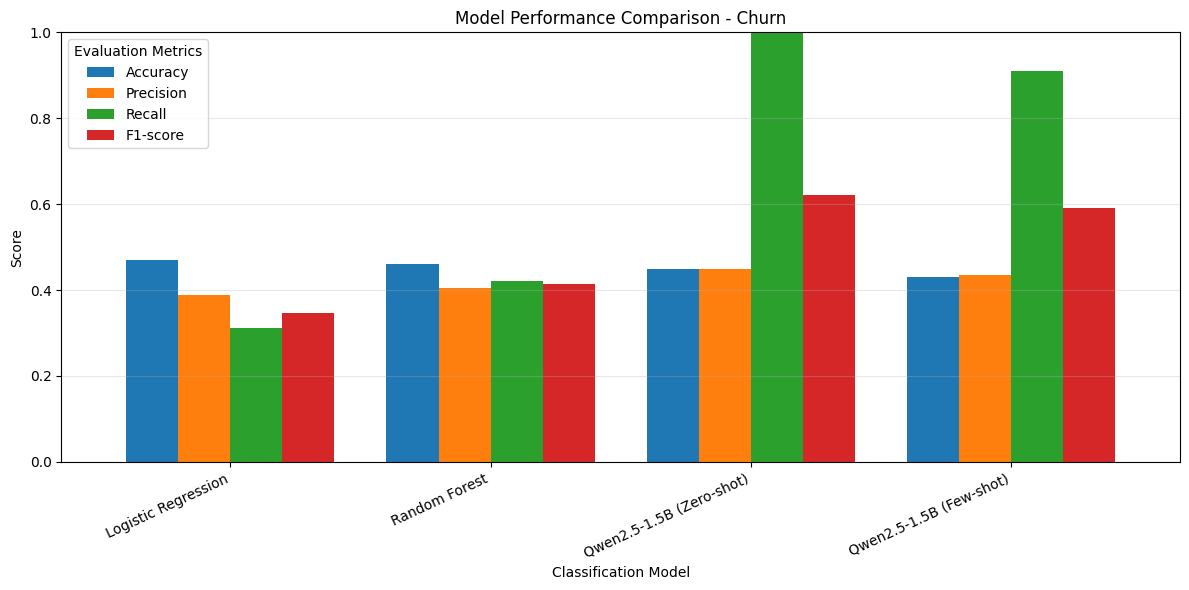

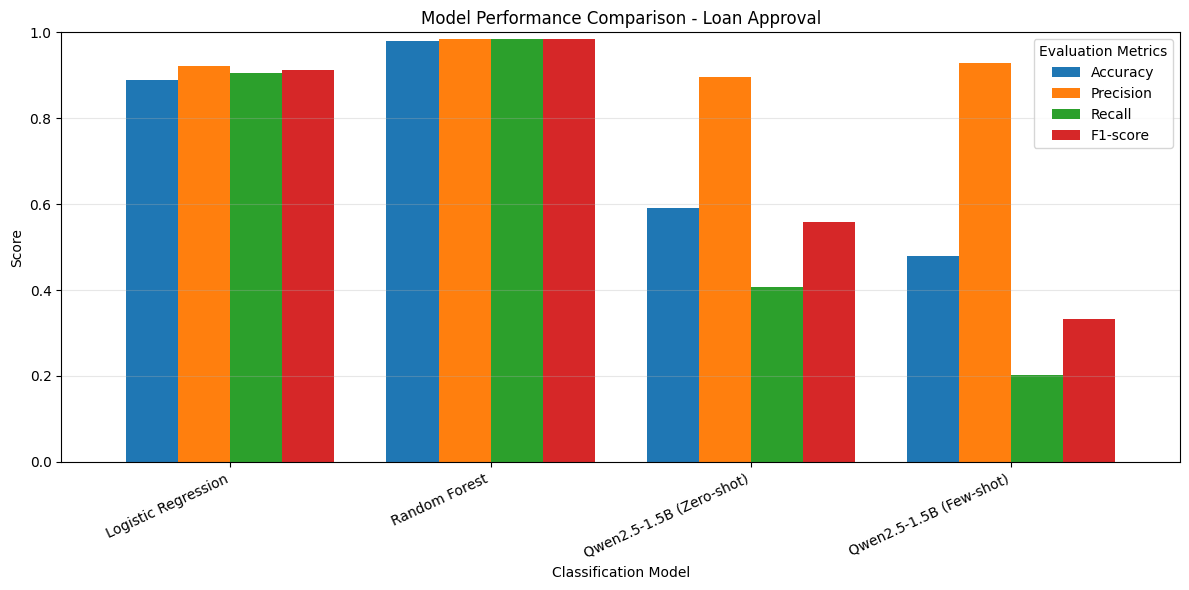

In [32]:

# STEP 26: VISUALISE MODEL PERFORMANCE

import matplotlib.pyplot as plt
import seaborn as sns

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-score']

for dataset in final_comparison_df['Dataset'].unique():

    subset = final_comparison_df[
        final_comparison_df['Dataset'] == dataset
    ]

    subset = subset.set_index('Model')

    ax = subset[metrics_to_plot].plot(
        kind='bar',
        figsize=(12, 6),
        ylim=(0, 1),
        width=0.8
    )

    plt.title(f'Model Performance Comparison - {dataset}')
    plt.xlabel('Classification Model')
    plt.ylabel('Score')
    plt.xticks(rotation=25, ha='right')
    plt.legend(title='Evaluation Metrics')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()

    filename = dataset.lower().replace(' ', '_')
    plt.savefig(
        os.path.join(RESULTS_PATH, f'{filename}_comparison.png'),
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()


In [33]:
print("Traditional models:", trained_models.keys())
print("Churn features:", list(X_churn.columns))
print("Loan features:", list(X_loan.columns))
print("LLM loaded:", "model" in globals() and "tokenizer" in globals())

Traditional models: dict_keys([('Churn', 'Logistic Regression'), ('Churn', 'Random Forest'), ('Loan Approval', 'Logistic Regression'), ('Loan Approval', 'Random Forest')])
Churn features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
Loan features: ['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
LLM loaded: True


In [34]:
import inspect

for name, obj in globals().copy().items():
    if callable(obj) and (
        "predict" in name.lower()
        or "few" in name.lower()
        or "prompt" in name.lower()
    ):
        try:
            print(f"\nFunction: {name}")
            print(inspect.signature(obj))
        except:
            pass


Function: create_classification_prompt
(record, task)

Function: predict_llm_batch
(records, task, batch_size=8)

Function: get_few_shot_examples
(X_train, y_train, examples_per_class=2)

Function: create_few_shot_prompt
(record, task, examples)

Function: predict_few_shot
(records, task, examples, batch_size=8)


In [35]:
!pip install -q fastapi uvicorn nest-asyncio

In [36]:
import inspect

print(inspect.getsource(create_classification_prompt))

def create_classification_prompt(record, task):
    features = "\n".join(
        f"{key}: {value}" for key, value in record.items()
    )

    if task == "Churn":
        instructions = """
You are a customer churn classification system.

Your task is to predict whether a customer will leave their
telecommunications service.

Possible labels:
- Yes: The customer will churn.
- No: The customer will not churn.

Analyse the customer information and choose the most likely label.
"""

    elif task == "Loan Approval":
        instructions = """
You are a loan approval classification system.

Your task is to predict the loan application outcome.

Possible labels:
- Approved: The loan application will be approved.
- Rejected: The loan application will be rejected.

Analyse the applicant information and choose the most likely label.
"""

    return f"""
{instructions}

Applicant/customer information:
{features}

Return only one label. Do not provide an explanation.
"""



In [37]:
churn_examples = get_few_shot_examples(
    X_churn_train,
    y_churn_train,
    examples_per_class=2
)

loan_examples = get_few_shot_examples(
    X_loan_train,
    y_loan_train,
    examples_per_class=2
)

print("Churn examples prepared:", len(churn_examples))
print("Loan examples prepared:", len(loan_examples))

Churn examples prepared: 4
Loan examples prepared: 4


In [38]:
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from typing import Dict, Any
import pandas as pd
import numpy as np

app = FastAPI(
    title="LLM and Traditional ML Classification API",
    description="API for customer churn and loan approval classification.",
    version="1.0.0"
)

class PredictionRequest(BaseModel):
    model: str
    features: Dict[str, Any]


AVAILABLE_MODELS = [
    "Logistic Regression",
    "Random Forest",
    "Qwen Zero-shot",
    "Qwen Few-shot"
]

DATASET_CONFIG = {
    "Churn": {
        "task": "Churn",
        "features": list(X_churn.columns),
        "examples": churn_examples
    },
    "Loan Approval": {
        "task": "Loan Approval",
        "features": list(X_loan.columns),
        "examples": loan_examples
    }
}


@app.get("/")
def home():
    return {
        "message": "Classification API is running",
        "available_datasets": ["Churn", "Loan Approval"],
        "available_models": AVAILABLE_MODELS
    }


@app.get("/health")
def health():
    return {"status": "healthy"}


def run_prediction(dataset, request):

    if request.model not in AVAILABLE_MODELS:
        raise HTTPException(
            status_code=400,
            detail=f"Invalid model. Choose from: {AVAILABLE_MODELS}"
        )

    config = DATASET_CONFIG[dataset]
    expected_features = config["features"]
    supplied_features = request.features

    missing = set(expected_features) - set(supplied_features)
    extra = set(supplied_features) - set(expected_features)

    if missing or extra:
        raise HTTPException(
            status_code=400,
            detail={
                "missing_features": sorted(missing),
                "unexpected_features": sorted(extra)
            }
        )

    # Arrange features in the same order used during training
    record = {
        feature: supplied_features[feature]
        for feature in expected_features
    }

    # Traditional ML prediction
    if request.model in ["Logistic Regression", "Random Forest"]:

        trained_model = trained_models[
            (dataset, request.model)
        ]

        input_df = pd.DataFrame([record])
        prediction = trained_model.predict(input_df)[0]

        if hasattr(trained_model, "predict_proba"):
            probabilities = trained_model.predict_proba(input_df)[0]
            confidence = float(max(probabilities))
        else:
            confidence = None

    # LLM zero-shot prediction
    elif request.model == "Qwen Zero-shot":

        prediction = predict_llm_batch(
            [record],
            config["task"]
        )[0]

        confidence = None

    # LLM few-shot prediction
    else:

        prediction = predict_few_shot(
            [record],
            config["task"],
            config["examples"]
        )[0]

        confidence = None

    return {
        "dataset": dataset,
        "model": request.model,
        "prediction": str(prediction),
        "confidence": confidence
    }


@app.post("/predict/churn")
def predict_churn(request: PredictionRequest):
    return run_prediction("Churn", request)


@app.post("/predict/loan")
def predict_loan(request: PredictionRequest):
    return run_prediction("Loan Approval", request)


print("API application created successfully!")

API application created successfully!


In [39]:
import nest_asyncio
import threading
import uvicorn
import time

nest_asyncio.apply()

def start_api():
    uvicorn.run(app, host="0.0.0.0", port=8000)

api_thread = threading.Thread(
    target=start_api,
    daemon=True
)

api_thread.start()

time.sleep(3)

print("API server started!")

INFO:     Started server process [674]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


API server started!


In [40]:
from google.colab.output import eval_js

api_url = eval_js("google.colab.kernel.proxyPort(8000)")

print("Your API URL:", api_url)
print("Swagger documentation:", api_url + "docs")

Your API URL: https://8000-gpu-t4-s-usw4b1-it900npzwggx-b.us-west4.prod.r.colab.dev
Swagger documentation: https://8000-gpu-t4-s-usw4b1-it900npzwggx-b.us-west4.prod.r.colab.devdocs


In [43]:
import requests

response = requests.get("http://127.0.0.1:8000/")

print("Status code:", response.status_code)
print("Response:", response.json())

INFO:     127.0.0.1:39052 - "GET / HTTP/1.1" 200 OK
Status code: 200
Response: {'message': 'Classification API is running', 'available_datasets': ['Churn', 'Loan Approval'], 'available_models': ['Logistic Regression', 'Random Forest', 'Qwen Zero-shot', 'Qwen Few-shot']}


In [44]:
churn_input = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 12,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "DSL",
    "OnlineSecurity": "No",
    "OnlineBackup": "Yes",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 55.5,
    "TotalCharges": 666.0
}

payload = {
    "model": "Random Forest",
    "features": churn_input
}

response = requests.post(
    "http://127.0.0.1:8000/predict/churn",
    json=payload
)

print("Status code:", response.status_code)
print("Prediction:", response.json())

INFO:     127.0.0.1:51916 - "POST /predict/churn HTTP/1.1" 200 OK
Status code: 200
Prediction: {'dataset': 'Churn', 'model': 'Random Forest', 'prediction': 'Yes', 'confidence': 0.675}


In [45]:
loan_input = {
    "no_of_dependents": 2,
    "education": "Graduate",
    "self_employed": "No",
    "income_annum": 5000000,
    "loan_amount": 15000000,
    "loan_term": 10,
    "cibil_score": 750,
    "residential_assets_value": 5000000,
    "commercial_assets_value": 2000000,
    "luxury_assets_value": 3000000,
    "bank_asset_value": 4000000
}

payload = {
    "model": "Random Forest",
    "features": loan_input
}

response = requests.post(
    "http://127.0.0.1:8000/predict/loan",
    json=payload
)

print("Status code:", response.status_code)
print("Prediction:", response.json())

INFO:     127.0.0.1:35320 - "POST /predict/loan HTTP/1.1" 200 OK
Status code: 200
Prediction: {'dataset': 'Loan Approval', 'model': 'Random Forest', 'prediction': 'Approved', 'confidence': 0.935}


In [46]:
models_to_test = [
    "Logistic Regression",
    "Random Forest",
    "Qwen Zero-shot",
    "Qwen Few-shot"
]

for selected_model in models_to_test:
    payload = {
        "model": selected_model,
        "features": churn_input
    }

    response = requests.post(
        "http://127.0.0.1:8000/predict/churn",
        json=payload
    )

    print("\nModel:", selected_model)
    print("Status:", response.status_code)
    print("Result:", response.json())

INFO:     127.0.0.1:46086 - "POST /predict/churn HTTP/1.1" 200 OK

Model: Logistic Regression
Status: 200
Result: {'dataset': 'Churn', 'model': 'Logistic Regression', 'prediction': 'No', 'confidence': 0.5099043226335915}
INFO:     127.0.0.1:46096 - "POST /predict/churn HTTP/1.1" 200 OK

Model: Random Forest
Status: 200
Result: {'dataset': 'Churn', 'model': 'Random Forest', 'prediction': 'Yes', 'confidence': 0.675}
INFO:     127.0.0.1:46108 - "POST /predict/churn HTTP/1.1" 200 OK

Model: Qwen Zero-shot
Status: 200
Result: {'dataset': 'Churn', 'model': 'Qwen Zero-shot', 'prediction': 'Yes', 'confidence': None}
INFO:     127.0.0.1:46114 - "POST /predict/churn HTTP/1.1" 200 OK

Model: Qwen Few-shot
Status: 200
Result: {'dataset': 'Churn', 'model': 'Qwen Few-shot', 'prediction': 'Yes', 'confidence': None}
